# Global Solution 2026/2 — Vaga Viva

**Disciplina:** Artificial Intelligence & Chatbot  
**Turma:** 1TDSPV  
**Integrantes:**

- Fabio Cezare Almeida — RM 572642
- Guilherme Zanfolim Nunes Farias — RM 570983
- Jaime Ringel — RM 562044
- Lucas Monteiro Dias da Costa — RM 571388
- Mateus Magalhães Romão de Moraes — RM 573371

**Fonte dos dados:** Joni Hoppen, *Medical Appointment No Shows*, Kaggle, versão 5 (20/08/2017).
<https://www.kaggle.com/datasets/joniarroba/noshowappointments>
Licença indicada na página do dataset: **CC BY-NC-SA 4.0**.


## Objetivo e decisões

Comparar Regressão Logística e Random Forest com pesos de classe para estimar a
probabilidade de falta. A divisão é cronológica: 64% inicial para ajuste, 16% seguinte para seleção e 20% final para teste. O teste final não participa da escolha do algoritmo. O histórico de cada linha usa somente consultas
em datas anteriores. O recall da classe falta é importante porque uma vaga perdida
pode ser oferecida a alguém da fila; ainda assim, o nível **nunca** cancela nem
nega atendimento.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import dump
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

raiz = Path.cwd().resolve()
if raiz.name == "notebooks":
    raiz = raiz.parent
base = (
    pd.read_csv(raiz / "dados" / "noshow_consultas.csv", parse_dates=["data_consulta"])
    .sort_values("data_consulta")
    .reset_index(drop=True)
)
pasta_modelos = raiz / "modelos"
pasta_modelos.mkdir(parents=True, exist_ok=True)

## Separação temporal e definição das características

In [2]:
FEATURES = [
    "idade", "dias_antecedencia", "mesmo_dia", "dia_semana",
    "recebeu_lembrete", "n_consultas_anteriores", "faltas_anteriores",
    "taxa_faltas_anterior", "primeira_consulta",
]
X = base[FEATURES].copy()
for coluna in ["mesmo_dia", "recebeu_lembrete", "primeira_consulta"]:
    X[coluna] = X[coluna].astype(int)
y = base["faltou"].astype(int)

datas = np.sort(base["data_consulta"].dropna().unique())
indice_corte_teste = int(len(datas) * 0.80)
data_corte_teste = pd.Timestamp(datas[indice_corte_teste])
datas_desenvolvimento = datas[:indice_corte_teste]
indice_corte_validacao = int(len(datas_desenvolvimento) * 0.80)
data_corte_validacao = pd.Timestamp(datas_desenvolvimento[indice_corte_validacao])
mascara_treino = base["data_consulta"] < data_corte_validacao
mascara_validacao = (
    (base["data_consulta"] >= data_corte_validacao)
    & (base["data_consulta"] < data_corte_teste)
)
mascara_teste = base["data_consulta"] >= data_corte_teste
X_treino, y_treino = X.loc[mascara_treino], y.loc[mascara_treino]
X_validacao, y_validacao = X.loc[mascara_validacao], y.loc[mascara_validacao]
X_teste, y_teste = X.loc[mascara_teste], y.loc[mascara_teste]
X_desenvolvimento = pd.concat([X_treino, X_validacao]).sort_index()
y_desenvolvimento = pd.concat([y_treino, y_validacao]).sort_index()
print(f"Ajuste: antes de {data_corte_validacao.date()} ? {len(X_treino):,} linhas")
print(f"Sele??o: de {data_corte_validacao.date()} at? {data_corte_teste.date()} ? {len(X_validacao):,} linhas")
print(f"Teste final: a partir de {data_corte_teste.date()} ? {len(X_teste):,} linhas")
print(f"Taxas de falta ? ajuste: {y_treino.mean():.2%}; sele??o: {y_validacao.mean():.2%}; teste: {y_teste.mean():.2%}")

Ajuste: antes de 2016-05-20 ? 63,532 linhas
Sele??o: de 2016-05-20 at? 2016-06-01 ? 20,539 linhas
Teste final: a partir de 2016-06-01 ? 26,450 linhas
Taxas de falta ? ajuste: 20.95%; sele??o: 20.08%; teste: 18.46%


## Comparação de algoritmos com classe desbalanceada

,acuracia,precisao_falta,recall_falta,f1_falta,roc_auc
Regress?o Log?stica,0.560641,0.300131,0.892095,0.449152,0.73265
Random Forest,0.664589,0.323818,0.616149,0.424526,0.716519


Regress?o Log?stica ? matriz [compareceu, faltou] na valida??o:


,Previsto n?o,Previsto sim
Real n?o,7836,8579
Real sim,445,3679


Random Forest ? matriz [compareceu, faltou] na valida??o:


,Previsto n?o,Previsto sim
Real n?o,11109,5306
Real sim,1583,2541


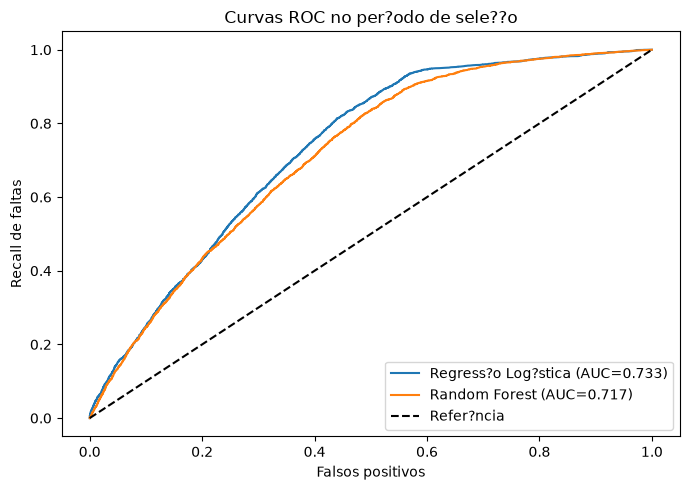

In [3]:
modelos_candidatos = {
    "Regress?o Log?stica": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1500, random_state=42),
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, class_weight="balanced_subsample",
        min_samples_leaf=4, random_state=42, n_jobs=-1,
    ),
}
resultados_validacao = {}
probabilidades_validacao = {}
for nome, modelo in modelos_candidatos.items():
    modelo.fit(X_treino, y_treino)
    probabilidade = modelo.predict_proba(X_validacao)[:, 1]
    previsao = (probabilidade >= 0.5).astype(int)
    probabilidades_validacao[nome] = probabilidade
    resultados_validacao[nome] = {
        "acuracia": accuracy_score(y_validacao, previsao),
        "precisao_falta": precision_score(y_validacao, previsao, zero_division=0),
        "recall_falta": recall_score(y_validacao, previsao, zero_division=0),
        "f1_falta": f1_score(y_validacao, previsao, zero_division=0),
        "roc_auc": roc_auc_score(y_validacao, probabilidade),
        "matriz_confusao": confusion_matrix(y_validacao, previsao).tolist(),
    }
tabela_resultados = pd.DataFrame(resultados_validacao).T
display(tabela_resultados.drop(columns="matriz_confusao").sort_values("roc_auc", ascending=False))
for nome, resultado in resultados_validacao.items():
    print(f"{nome} ? matriz [compareceu, faltou] na valida??o:")
    display(pd.DataFrame(resultado["matriz_confusao"], index=["Real n?o", "Real sim"], columns=["Previsto n?o", "Previsto sim"]))

fig, eixo = plt.subplots(figsize=(7, 5))
for nome, probs in probabilidades_validacao.items():
    fpr, tpr, _ = roc_curve(y_validacao, probs)
    eixo.plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_validacao, probs):.3f})")
eixo.plot([0, 1], [0, 1], "k--", label="Refer?ncia")
eixo.set(title="Curvas ROC no per?odo de sele??o", xlabel="Falsos positivos", ylabel="Recall de faltas")
eixo.legend()
plt.tight_layout()
plt.show()

Modelo-base escolhido pela valida??o temporal (ROC-AUC; desempate por F1): Regress?o Log?stica
O teste final permaneceu separado da sele??o do modelo.
Probabilidades calibradas por sigmoide temporal com 4 blocos no conjunto de desenvolvimento.
M?tricas finais no teste, limiar operacional 0.20: {'acuracia': 0.541398865784499, 'precisao_falta': 0.27103866565579987, 'recall_falta': 0.8787382220401475, 'f1_falta': 0.41429261226460645, 'roc_auc': 0.7218117225270083}
Matriz final [compareceu, faltou], no teste:


,Previsto n?o,Previsto sim
Real n?o,10030,11538
Real sim,592,4290


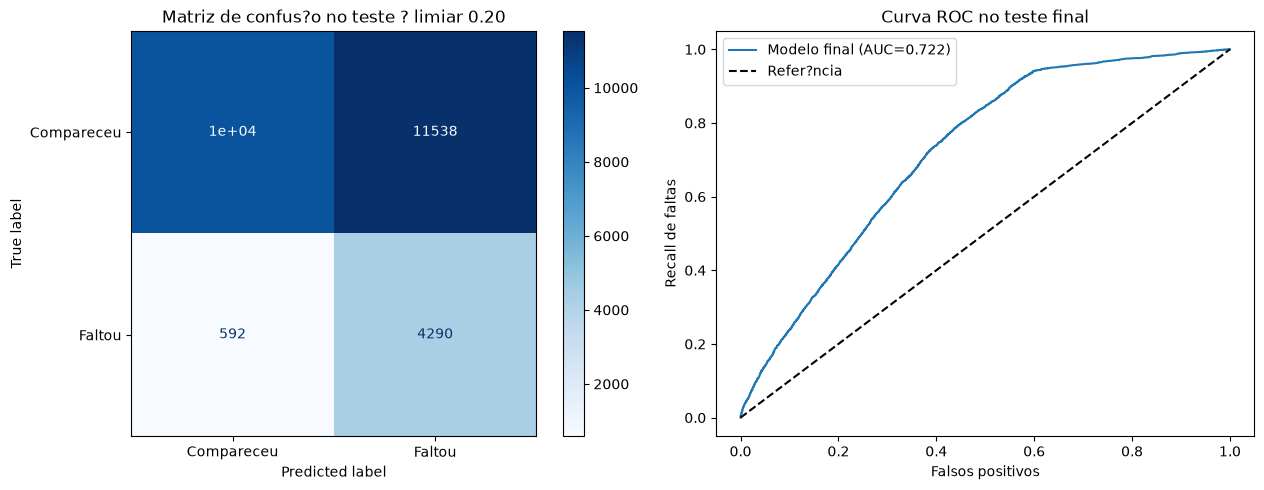

In [4]:
escolhido = max(
    resultados_validacao,
    key=lambda nome: (resultados_validacao[nome]["roc_auc"], resultados_validacao[nome]["f1_falta"]),
)
modelo_base = modelos_candidatos[escolhido]
modelo_final = CalibratedClassifierCV(
    estimator=modelo_base,
    method="sigmoid",
    cv=TimeSeriesSplit(n_splits=4),
)
modelo_final.fit(X_desenvolvimento, y_desenvolvimento)
prob_teste = modelo_final.predict_proba(X_teste)[:, 1]
limiar_operacional = 0.20
previsao_operacional = (prob_teste >= limiar_operacional).astype(int)
metricas_operacionais = {
    "acuracia": accuracy_score(y_teste, previsao_operacional),
    "precisao_falta": precision_score(y_teste, previsao_operacional, zero_division=0),
    "recall_falta": recall_score(y_teste, previsao_operacional, zero_division=0),
    "f1_falta": f1_score(y_teste, previsao_operacional, zero_division=0),
    "roc_auc": roc_auc_score(y_teste, prob_teste),
}
print(f"Modelo-base escolhido pela valida??o temporal (ROC-AUC; desempate por F1): {escolhido}")
print("O teste final permaneceu separado da sele??o do modelo.")
print("Probabilidades calibradas por sigmoide temporal com 4 blocos no conjunto de desenvolvimento.")
print(f"M?tricas finais no teste, limiar operacional {limiar_operacional:.2f}: {metricas_operacionais}")
print("Matriz final [compareceu, faltou], no teste:")
display(pd.DataFrame(
    confusion_matrix(y_teste, previsao_operacional),
    index=["Real n?o", "Real sim"],
    columns=["Previsto n?o", "Previsto sim"],
))

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsao_operacional, display_labels=["Compareceu", "Faltou"],
    cmap="Blues", ax=eixos[0],
)
eixos[0].set_title(f"Matriz de confus?o no teste ? limiar {limiar_operacional:.2f}")
fpr, tpr, _ = roc_curve(y_teste, prob_teste)
eixos[1].plot(fpr, tpr, label=f"Modelo final (AUC={metricas_operacionais['roc_auc']:.3f})")
eixos[1].plot([0, 1], [0, 1], "k--", label="Refer?ncia")
eixos[1].set(title="Curva ROC no teste final", xlabel="Falsos positivos", ylabel="Recall de faltas")
eixos[1].legend()
fig.tight_layout()
plt.show()

## Importância das variáveis

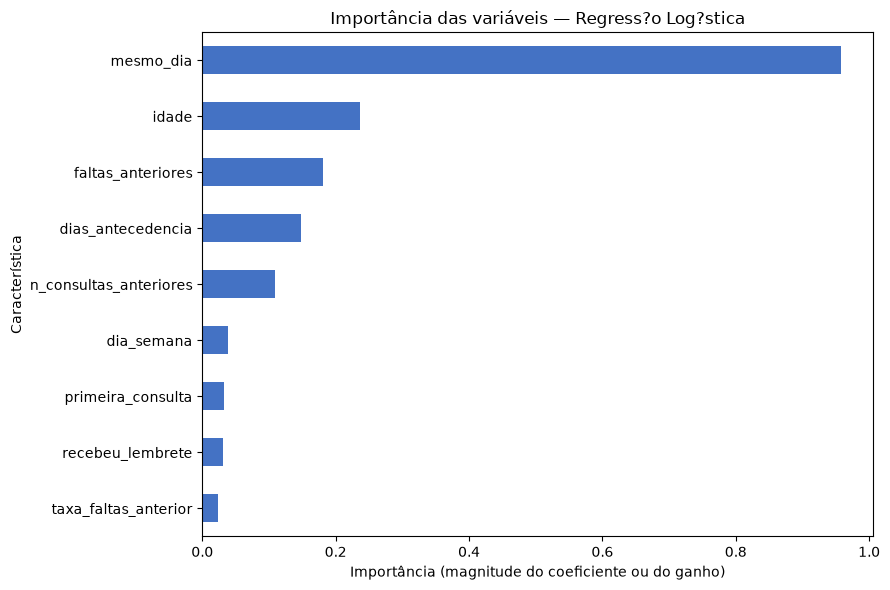

,importancia
mesmo_dia,0.957597
idade,0.236241
faltas_anteriores,0.180381
dias_antecedencia,0.147392
n_consultas_anteriores,0.109663
dia_semana,0.037871
primeira_consulta,0.032739
recebeu_lembrete,0.031559
taxa_faltas_anterior,0.023154


In [5]:
estimador = modelo_base[-1] if hasattr(modelo_base, "__getitem__") else modelo_base
if hasattr(estimador, "feature_importances_"):
    importancia = pd.Series(estimador.feature_importances_, index=FEATURES)
else:
    importancia = pd.Series(np.abs(estimador.coef_[0]), index=FEATURES)
importancia = importancia.sort_values()
importancia.plot.barh(figsize=(9, 6), color="#4472C4")
plt.title(f"Importância das variáveis — {escolhido}")
plt.xlabel("Importância (magnitude do coeficiente ou do ganho)")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()
display(importancia.sort_values(ascending=False).to_frame("importancia"))

## Faixas de risco e análise observada

Usamos inicialmente as faixas de referência do projeto: BAIXO < 0,20;
MÉDIO de 0,20 a 0,35; ALTO > 0,35. A tabela abaixo mede a distribuição
das probabilidades e a taxa real de falta no conjunto de teste. Os níveis
não são decisões clínicas e só orientam a ordem do contato.

In [6]:
faixas = np.select(
    [prob_teste < 0.20, prob_teste <= 0.35],
    ["BAIXO", "MEDIO"],
    default="ALTO",
)
analise_faixas = pd.DataFrame({"nivel": faixas, "faltou": y_teste.to_numpy()}).groupby(
    "nivel", observed=False
).agg(consultas=("faltou", "size"), taxa_real_falta=("faltou", "mean"))
display(analise_faixas)
print("Distribuição de probabilidades no teste:")
display(pd.Series(prob_teste).describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("probabilidade_falta"))

,consultas,taxa_real_falta
nivel,,
ALTO,3528,0.346655
BAIXO,10622,0.055733
MEDIO,12300,0.249350


Distribuição de probabilidades no teste:


,probabilidade_falta
count,26450.000000
mean,0.211811
std,0.138832
min,0.000401
10%,0.039964
25%,0.058414
50%,0.229993
75%,0.304392
90%,0.372610
max,0.953412


## Motivos curtos para a API

In [7]:
def gerar_motivos(entrada):
    motivos = []
    if entrada["dias_antecedencia"] > 30:
        motivos.append(f"Agendada há {entrada['dias_antecedencia']} dias")
    if not entrada["recebeu_lembrete"]:
        motivos.append("Sem lembrete")
    if entrada["primeira_consulta"]:
        motivos.append("Primeira consulta")
    elif entrada["faltas_anteriores"] > 0:
        motivos.append(
            f"Faltou em {entrada['faltas_anteriores']} das "
            f"{entrada['n_consultas_anteriores']} consultas anteriores"
        )
    return motivos[:3]

print("Motivos são regras descritivas da entrada, não explicações causais.")

Motivos são regras descritivas da entrada, não explicações causais.


## Exportação do modelo e configuração

In [8]:
dump(modelo_final, pasta_modelos / "modelo_falta.joblib")
configuracao = {
    "features_falta": FEATURES,
    "limites_risco": {
        "baixo_maximo_exclusivo": 0.20,
        "medio_maximo_inclusivo": 0.35,
    },
    "niveis_risco": {
        "baixo": "BAIXO",
        "medio": "MEDIO",
        "alto": "ALTO",
    },
    "modelo_falta": {
        "algoritmo": escolhido,
        "calibracao": "sigmoide temporal (TimeSeriesSplit, 4 blocos)",
        "criterio_selecao": "maior ROC-AUC no per?odo de sele??o; desempate por F1 da classe falta; teste final reservado para avalia??o",
    },
    "features_perfil": [
        "idade", "dias_antecedencia_media", "taxa_faltas_anterior",
        "taxa_lembretes_anterior", "n_consultas_anteriores",
    ],
    "perfis": {},
}
caminho_config = pasta_modelos / "config_modelos.json"
configuracao_existente = (
    json.loads(caminho_config.read_text(encoding="utf-8"))
    if caminho_config.exists()
    else {}
)
configuracao["features_perfil"] = configuracao_existente.get(
    "features_perfil", configuracao["features_perfil"]
)
configuracao["perfis"] = configuracao_existente.get("perfis", {})
if "agrupamento_perfil" in configuracao_existente:
    configuracao["agrupamento_perfil"] = configuracao_existente["agrupamento_perfil"]
caminho_config.write_text(json.dumps(configuracao, ensure_ascii=False, indent=2), encoding="utf-8")
print("Modelo e configuração exportados:", pasta_modelos)

Modelo e configuração exportados: C:\Users\User\Desktop\vagaviva-ia\modelos


## Conclusão

A comparação foi feita em período futuro em relação ao treino, com
métricas para a classe faltou e ROC-AUC. O modelo selecionado e suas
métricas acima são resultados da execução deste notebook. O risco
apenas prioriza a confirmação/contato e jamais cancela ou nega consulta.